In [12]:
from math import *
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
import os
import sunpy.map

data_dir = 'E:/Research/Data/CHASE/HIS/AR3664/'
save_dir = 'E:/Research/Work/202405_solar_storm/Doppler/'
save_or_not = 0

In [24]:
## Defining HIS range function
def get_HIS_coord_range(CRVAL2, CRVAL3, NAXIS1, NAXIS2):
    '''''
    This function is used to get the coordinate range of HIS image.
    '''''
    xlim = [CRVAL2, CRVAL2 + NAXIS1]
    ylim = [CRVAL3, CRVAL3 + NAXIS2]
    
    return xlim, ylim

## Defining co-alignment function
def coalign_HMi2HIS(Br, xlim, ylim):
    '''''
    This function is used to co-align HMI image to HIS image. It is rather rough.
    '''''
    Rs_pixel = 1882
    Rs_arcsec = 960
    nx = Br.shape[0] # 4096
    ny = Br.shape[1] # 4096
    
    idx_min = int(nx / 2 + xlim[0] / Rs_arcsec * Rs_pixel)
    idx_max = int(nx / 2 + xlim[1] / Rs_arcsec * Rs_pixel)
    idy_min = int(ny / 2 + ylim[0] / Rs_arcsec * Rs_pixel)
    idy_max = int(ny / 2 + ylim[1] / Rs_arcsec * Rs_pixel)
    
    print(idx_min)
    
    Br_cut = Br[idx_min:idx_max, idy_min:idy_max]
    nx_cut, ny_cut = Br_cut.shape
    
    x_cut = np.linspace(xlim[0], xlim[1], nx_cut)
    y_cut = np.linspace(ylim[0], ylim[1], ny_cut)
    xx_cut, yy_cut = np.meshgrid(x_cut, y_cut)
    
    return Br_cut, xx_cut, yy_cut

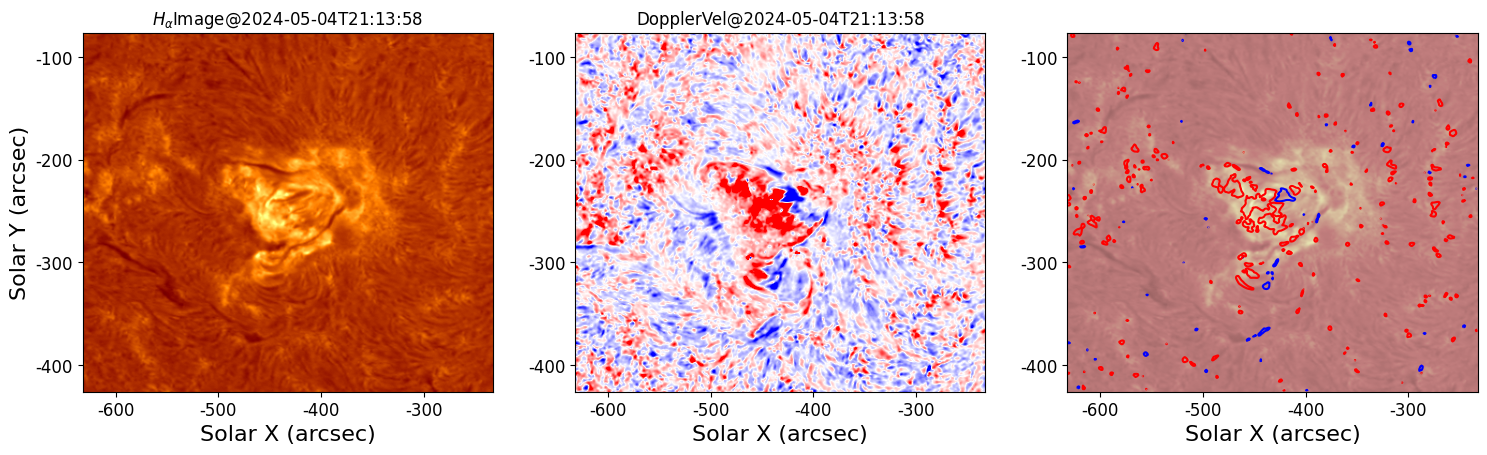

In [35]:
# Plotting CHASE/HIS H-alpha and Doppler image
cropHA_files = [f for f in os.listdir(data_dir) if f.startswith('cropHA') and f.endswith('.fits')]
Doppler_files = [f for f in os.listdir(data_dir) if f.startswith('Doppler') and f.endswith('.fits')]

common_times = set([f[6:-5] for f in cropHA_files]).intersection([f[7:-5] for f in Doppler_files])

for time in common_times:
    rsm_file = f'cropHA{time}.fits'
    dop_file = f'Doppler{time}.fits'
        
    rsm = fits.open(os.path.join(data_dir, rsm_file))
    dop = fits.open(os.path.join(data_dir, dop_file))
    CRPIX2, CRVAL2, CDELT2 = rsm[1].header['CRPIX2'], rsm[1].header['CRVAL2'], rsm[1].header['CDELT2']
    CRPIX3, CRVAL3, CDELT3 = rsm[1].header['CRPIX3'], rsm[1].header['CRVAL3'], rsm[1].header['CDELT3']
    pix_res_chase = 1.0436

    if floor(CRVAL2 / 50) == CRVAL2 / 50:
        xlabels = [floor(CRVAL2 / 50) * 50 + 100 * i for i in range(5)]
    if floor(CRVAL2 / 50) != CRVAL2 / 50:
        xlabels = [floor(CRVAL2 / 50 + 1) * 50 + 100 * i for i in range(4)]
    xticks = [(xlabels[i] - CRVAL2) / pix_res_chase + CRPIX2 for i in range(len(xlabels))]

    if floor(CRVAL3 / 50) == CRVAL3 / 50:
        ylabels = [floor(CRVAL3 / 50) * 50 + 100 * i for i in range(4)]
    if floor(CRVAL3 / 50) != CRVAL3 / 50:
        ylabels = [floor(CRVAL3 / 50 + 1) * 50 + 100 * i for i in range(4)]
    yticks = [(ylabels[i] - CRVAL3) / pix_res_chase + CRPIX3 for i in range(len(ylabels))]

    plt.figure(figsize = (18, 5))

    plt.subplot(131)
    plt.imshow(rsm[1].data[70], origin = 'lower', \
        cmap = 'afmhot', vmin = 0, vmax = rsm[1].data[70][-30:, -130:-100].mean() * 2.8)
    plt.xticks(xticks, xlabels, size = 12)
    plt.yticks(yticks, ylabels, size = 12)
    plt.xlabel('Solar X (arcsec)', size = 16)
    plt.ylabel('Solar Y (arcsec)', size = 16)
    plt.title(r'$H_{\alpha}$Image@' + rsm[1].header['DATE_OBS'])

    plt.subplot(132)
    plt.imshow(dop[1].data, origin = 'lower', cmap = 'bwr', vmin = -3, vmax = 3)
    plt.xticks(xticks, xlabels, size = 12)
    plt.yticks(yticks, ylabels, size = 12)
    plt.xlabel('Solar X (arcsec)', size = 16)
    # plt.ylabel('Solar Y (arcsec)', size = 16)
    plt.title('DopplerVel@' + rsm[1].header['DATE_OBS'])

    plt.subplot(133)
    plt.imshow(rsm[1].data[70], origin = 'lower', \
        cmap = 'pink', vmin = 0, vmax = rsm[1].data[70][-30:, -130:-100].mean() * 2.8)
    plt.contour(dop[1].data, levels=[-3,3], cmap = 'bwr')
    plt.xticks(xticks, xlabels, size = 12)
    plt.yticks(yticks, ylabels, size = 12)
    plt.xlabel('Solar X (arcsec)', size = 16)
    # plt.ylabel('Solar Y (arcsec)', size = 16)
    
    date_obs = rsm[1].header['DATE_OBS'].replace('-', '').replace(':', '')
    file_name = f'Doppler{date_obs}.png'
    save_path = os.path.join(save_dir, file_name)

    if save_or_not == 1:
        plt.savefig(save_path)
        plt.close()
    else: 
        plt.show()
        break
    
    rsm.close()
    dop.close()

See https://docs.sunpy.org/en/stable/code_ref/map.html#fixing-map-metadata for how to fix metadata before loading it with sunpy.map.Map.
See https://fits.gsfc.nasa.gov/fits_standard.html forthe FITS unit standards. [sunpy.map.mapbase]


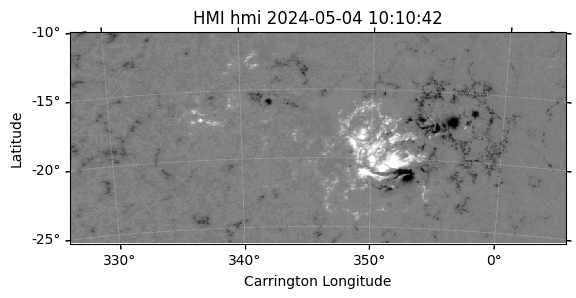

In [10]:
# Plotting HMI/SHARP data
record_date = '20240508'
record_time = '120000'

file = 'E:/Research/Data/SDO/HMI/SHARP/AR3664/hmi.sharp_cea_720s.11149.20240504_101200_TAI.Br.fits'

sharp_map = sunpy.map.Map(file)
fig = plt.figure()
ax = fig.add_subplot(projection=sharp_map)
sharp_map.plot(axes=ax, vmin=-1500, vmax=1500)

plt.show()